<a href="https://colab.research.google.com/github/BarGinger/Deep_Learning_MEG/blob/main/notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Deep Learning - Assigment 2

### Group Number: 22

### Teammates:
1. **Mahshid Jafar Tajrishi**
2. **Bar Melinarskiy**
3. **Cis van Aken**
4. **Simon van Klompenburg**

## Imports entire notebook

In [1]:
# Helper function to check if the code is running in Google Colab
def is_colab():
    try:
        import google.colab
        return True
    except ImportError:
        return False

# Usage
if is_colab():
    print("Running in Google Colab")
else:
    print("Not running in Google Colab")


# Importing libraries
import pandas as pd
import numpy as np
import Models
import utils as utils
import torch
import matplotlib.pyplot as plt
import os
import random
import datetime
import importlib
importlib.reload(utils)
importlib.reload(Models)

Not running in Google Colab


<module 'Models' (namespace) from ['c:\\Users\\bar24\\OneDrive - Universiteit Utrecht\\Documents\\School\\UU Data Sceince MSc\\1st Year\\Period 4\\Deep learning (INFOMDLR)\\Assignments\\Deep_Learning_MEG\\Models']>

## Global Definitions

In [2]:
# Path to the zip file
data_dir = "./Data"
google_drive_folder = "/content/drive/MyDrive/UU"
zip_path = f"{data_dir}/Final Project data.zip"
output_dir = "./Output"
model_dir = "./Models"

# check if outpiut directory exists
if not os.path.exists(output_dir):
    os.makedirs(output_dir)

# check if model directory exists
if not os.path.exists(model_dir):
    os.makedirs(model_dir)

# Set the device to GPU if available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

debug_mode = False

# Set pandas display options to show all columns
pd.set_option('display.max_columns', None)

# Set random seed for reproducibility
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

# model and data related parameters
scaler_type = utils.NormalizationType.Z_SCORE_LOCAL  # or MINMAX_LOCAL, Z_SCORE_TIMEWISE
which_dataset = "intra"  # or "cross"
downsample = True  # or False
downsample_rate = 0  
if downsample:
    downsample_rate = 7

### Check if we are in google colab then we need to mount the drive

In [3]:
# If we are in colab and we need to mount the drive
if is_colab():
  from google.colab import drive
  # Mount Google Drive
  drive.mount('/content/drive')
  print("Google Drive mounted successfully.")
  data_dir = f"{google_drive_folder}/Final Project data"
else:
  print("Not in Google Colab.")

Not in Google Colab.


### Check if we have cude

In [4]:
# Check if CUDA is available
print(torch.__version__)
print(torch.version.cuda)  # Should match CUDA 12.5
print(torch.backends.cudnn.version())  # Should return a version, not None
print(torch.cuda.is_available())  # Should return True

2.5.1
None
90100
True


### Extract the Zip File

In [5]:
import zipfile

# Check if the dataset is already extracted, if not extract it
if not os.path.exists(data_dir):
    print("Extracting the dataset...")
    #unzip
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(data_dir)
    #list files in the extracted dir
    os.listdir(data_dir)
else:
    print("Dataset already extracted.")

Dataset already extracted.


### Load one example

Matrix shape: (248, 35624)


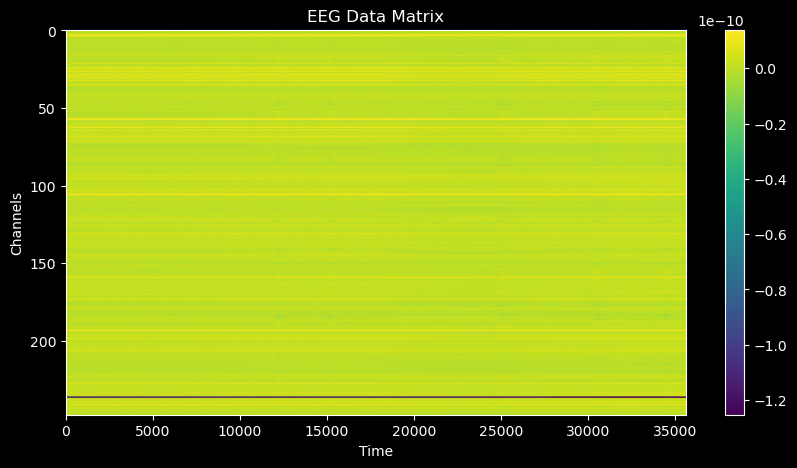

In [6]:
## peak into a matrix to see the data
matrix = utils.get_dataset_from_h5py(f"{data_dir}/Intra/train/task_working_memory_105923_3.h5")
if matrix is not None:
    print(f"Matrix shape: {matrix.shape}")


# plot that matrix
plt.figure(figsize=(10, 5))
plt.imshow(matrix, aspect='auto', cmap='viridis')
plt.colorbar()
plt.title("EEG Data Matrix")
plt.xlabel("Time")
plt.ylabel("Channels")
plt.show()

### Load the datasets

In [7]:
train_data, train_df, test_data, test_df = utils.load_dataset(
    which_dataset=which_dataset,
    data_dir=data_dir,
    scaler_type=scaler_type,
    downsample_rate=downsample_rate
)

Loading intra dataset...
Loading cached: Data\Normalized\z_score_local\intra_train_scaled.pt
Loading cached: Data\Normalized\z_score_local\intra_test_scaled.pt
Data for dataset intra was loaded successfully


### Definitions for training and logging

In [8]:
print("train task types counts:")
print(np.bincount(train_df['task_type'].astype('category').cat.codes))
print("test task types counts:")
print(np.bincount(test_df['task_type'].astype('category').cat.codes))


timestamp = datetime.datetime.now().strftime("%Y%m%d_%H%M%S")
# Set this once at the top of your notebook/cell
MODEL_NAME = utils.ModelClass.__name__ # "MEGClassifier"
print(f"Using model class: {MODEL_NAME}")
model_name = f"{MODEL_NAME}_{which_dataset}"
model_pth_path = f"{model_dir}/{which_dataset}/best_model_{model_name}_{timestamp}.pth"
model_csv_path = f"{output_dir}/{which_dataset}/best_model_{model_name}_{timestamp}.csv"
model_json_path = f"{model_dir}/{which_dataset}/best_model_{model_name}_{timestamp}.json"
best_model = None

# create folders if they do not exist
if not os.path.exists(f"{model_dir}/{which_dataset}"):
    os.makedirs(f"{model_dir}/{which_dataset}")


if not os.path.exists(f"{output_dir}/{which_dataset}"):
    os.makedirs(f"{output_dir}/{which_dataset}")

train task types counts:
[8 8 8 8]
test task types counts:
[2 2 2 2]
Using model class: MultiviewAttention


### Training stage #1 - fine-tuning using cross validation and optuna

[I 2025-06-01 22:51:49,336] A new study created in memory with name: no-name-dd376e44-ca0d-448e-acff-5970fd8e0775
c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains (3, 3) which is of type tuple.
  warnings.warn(message)
c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains (5, 5) which is of type tuple.
  warnings.warn(message)


Trial: 1, Fold index: 1:   0%|          | 0/50 [00:00<?, ?epoch/s]

c:\Users\bar24\OneDrive - Universiteit Utrecht\Documents\School\UU Data Sceince MSc\1st Year\Period 4\Deep learning (INFOMDLR)\Assignments\Deep_Learning_MEG\utils.py:760: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  all_metrics_df = pd.concat([all_metrics_df, pd.DataFrame([row])], ignore_index=True)


Early stopping triggered after 44 epochs (no val_loss improvement).


Trial: 1, Fold index: 2:   0%|          | 0/50 [00:00<?, ?epoch/s]

Early stopping triggered after 45 epochs (no val_loss improvement).


Trial: 1, Fold index: 3:   0%|          | 0/50 [00:00<?, ?epoch/s]

Early stopping triggered after 27 epochs (no val_loss improvement).


Trial: 1, Fold index: 4:   0%|          | 0/50 [00:00<?, ?epoch/s]

Early stopping triggered after 28 epochs (no val_loss improvement).


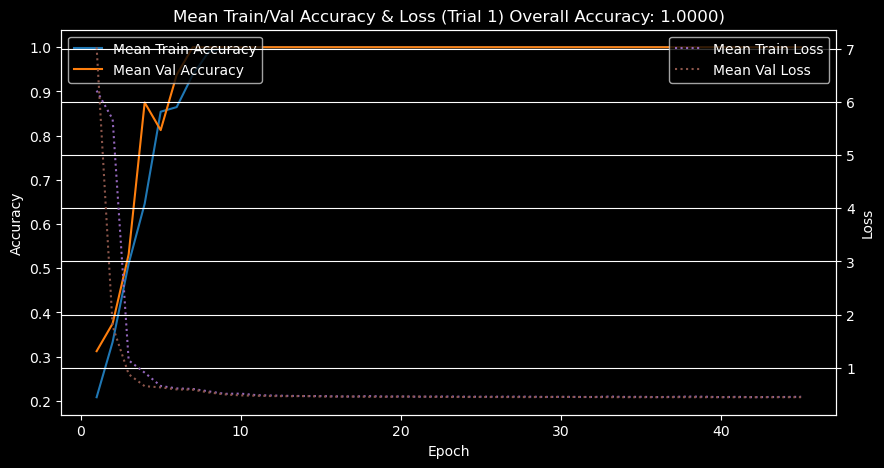

[I 2025-06-01 22:53:07,371] Trial 0 finished with value: 1.0 and parameters: {'window_size': 8, 'conv3_filters': 64, 'conv1_kernel_shape': (5, 5), 'conv2_kernel_shape': (3, 3), 'conv3_kernel_shape': (5, 5), 'padding1': 2, 'padding2': 1, 'padding3': 2, 'conv1_activation': 'gelu', 'conv2_activation': 'leaky_relu', 'conv3_activation': 'elu', 'dense_nodes': 128, 'dense_activation': 'relu', 'lstm1_cells': 32, 'lstm2_cells': 64, 'dense3_nodes': 64, 'dense3_activation': 'relu', 'learning_rate': 0.0010162181230224056, 'batch_size': 8, 'dropout_rate': 0.1, 'optimizer': 'adam', 'weight_decay': 8.687347627435256e-07, 'label_smoothing': 0.15, 'number_of_heads': 2}. Best is trial 0 with value: 1.0.


Trial 0 - Best Avg Val Acc: 1.0, Best Avg Val Loss: 0.8347923670496259


c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains (3, 3) which is of type tuple.
  warnings.warn(message)
c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains (5, 5) which is of type tuple.
  warnings.warn(message)


Trial: 2, Fold index: 1:   0%|          | 0/50 [00:00<?, ?epoch/s]

Early stopping triggered after 34 epochs (no val_loss improvement).


Trial: 2, Fold index: 2:   0%|          | 0/50 [00:00<?, ?epoch/s]

Early stopping triggered after 32 epochs (no val_loss improvement).


Trial: 2, Fold index: 3:   0%|          | 0/50 [00:00<?, ?epoch/s]

Early stopping triggered after 37 epochs (no val_loss improvement).


Trial: 2, Fold index: 4:   0%|          | 0/50 [00:00<?, ?epoch/s]

Early stopping triggered after 36 epochs (no val_loss improvement).


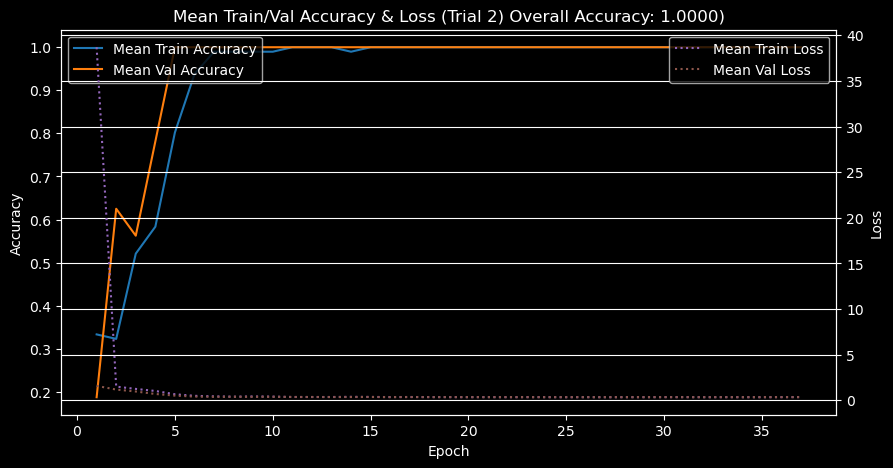

[I 2025-06-01 22:55:15,710] Trial 1 finished with value: 1.0 and parameters: {'window_size': 4, 'conv3_filters': 256, 'conv1_kernel_shape': (5, 5), 'conv2_kernel_shape': (5, 5), 'conv3_kernel_shape': (3, 3), 'padding1': 1, 'padding2': 2, 'padding3': 2, 'conv1_activation': 'leaky_relu', 'conv2_activation': 'leaky_relu', 'conv3_activation': 'elu', 'dense_nodes': 128, 'dense_activation': 'gelu', 'lstm1_cells': 64, 'lstm2_cells': 128, 'dense3_nodes': 32, 'dense3_activation': 'relu', 'learning_rate': 0.0017376418333673153, 'batch_size': 4, 'dropout_rate': 0.05, 'optimizer': 'adam', 'weight_decay': 9.184629372813147e-07, 'label_smoothing': 0.1, 'number_of_heads': 4}. Best is trial 0 with value: 1.0.


Trial 1 - Best Avg Val Acc: 1.0, Best Avg Val Loss: 0.45086901510755223


c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains (3, 3) which is of type tuple.
  warnings.warn(message)
c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains (5, 5) which is of type tuple.
  warnings.warn(message)


Trial: 3, Fold index: 1:   0%|          | 0/50 [00:00<?, ?epoch/s]

Early stopping triggered after 25 epochs (no val_loss improvement).


Trial: 3, Fold index: 2:   0%|          | 0/50 [00:00<?, ?epoch/s]

Early stopping triggered after 27 epochs (no val_loss improvement).


Trial: 3, Fold index: 3:   0%|          | 0/50 [00:00<?, ?epoch/s]

Early stopping triggered after 39 epochs (no val_loss improvement).


Trial: 3, Fold index: 4:   0%|          | 0/50 [00:00<?, ?epoch/s]

Early stopping triggered after 23 epochs (no val_loss improvement).


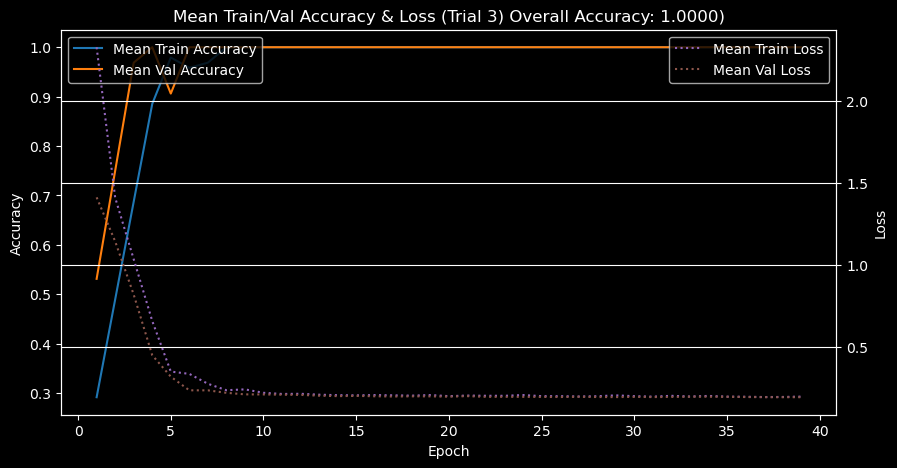

[I 2025-06-01 22:56:35,718] Trial 2 finished with value: 1.0 and parameters: {'window_size': 4, 'conv3_filters': 256, 'conv1_kernel_shape': (5, 5), 'conv2_kernel_shape': (5, 5), 'conv3_kernel_shape': (5, 5), 'padding1': 2, 'padding2': 2, 'padding3': 2, 'conv1_activation': 'leaky_relu', 'conv2_activation': 'leaky_relu', 'conv3_activation': 'relu', 'dense_nodes': 128, 'dense_activation': 'relu', 'lstm1_cells': 64, 'lstm2_cells': 128, 'dense3_nodes': 64, 'dense3_activation': 'gelu', 'learning_rate': 0.0005113838955214126, 'batch_size': 8, 'dropout_rate': 0.05, 'optimizer': 'adam', 'weight_decay': 4.05522500084055e-05, 'label_smoothing': 0.05, 'number_of_heads': 2}. Best is trial 0 with value: 1.0.


Trial 2 - Best Avg Val Acc: 1.0, Best Avg Val Loss: 0.3029503608527391


c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains (3, 3) which is of type tuple.
  warnings.warn(message)
c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains (5, 5) which is of type tuple.
  warnings.warn(message)


Trial: 4, Fold index: 1:   0%|          | 0/50 [00:00<?, ?epoch/s]

Early stopping triggered after 39 epochs (no val_loss improvement).


Trial: 4, Fold index: 2:   0%|          | 0/50 [00:00<?, ?epoch/s]

Early stopping triggered after 34 epochs (no val_loss improvement).


Trial: 4, Fold index: 3:   0%|          | 0/50 [00:00<?, ?epoch/s]

Early stopping triggered after 41 epochs (no val_loss improvement).


Trial: 4, Fold index: 4:   0%|          | 0/50 [00:00<?, ?epoch/s]

Early stopping triggered after 38 epochs (no val_loss improvement).


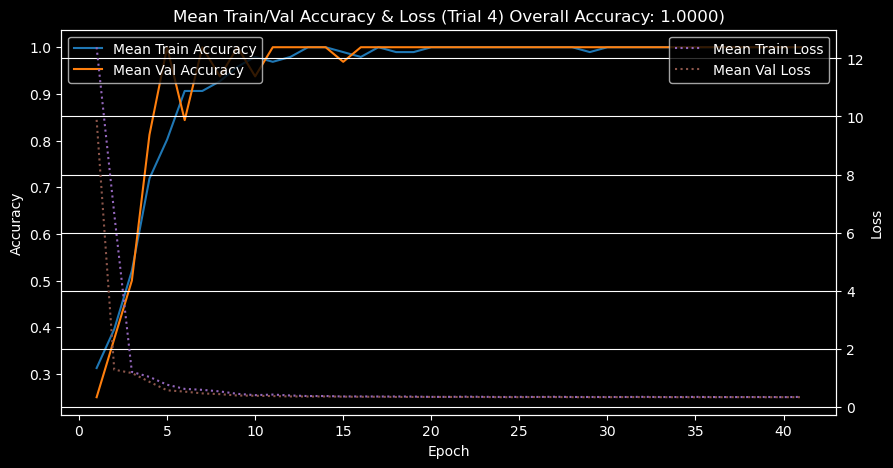

[I 2025-06-01 22:57:57,755] Trial 3 finished with value: 1.0 and parameters: {'window_size': 8, 'conv3_filters': 64, 'conv1_kernel_shape': (3, 3), 'conv2_kernel_shape': (3, 3), 'conv3_kernel_shape': (3, 3), 'padding1': 2, 'padding2': 1, 'padding3': 2, 'conv1_activation': 'leaky_relu', 'conv2_activation': 'leaky_relu', 'conv3_activation': 'elu', 'dense_nodes': 128, 'dense_activation': 'gelu', 'lstm1_cells': 32, 'lstm2_cells': 64, 'dense3_nodes': 64, 'dense3_activation': 'gelu', 'learning_rate': 0.0016832146267967663, 'batch_size': 8, 'dropout_rate': 0.1, 'optimizer': 'adam', 'weight_decay': 7.045480314321445e-05, 'label_smoothing': 0.1, 'number_of_heads': 2}. Best is trial 0 with value: 1.0.


Trial 3 - Best Avg Val Acc: 1.0, Best Avg Val Loss: 0.6196263691312388


c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains (3, 3) which is of type tuple.
  warnings.warn(message)
c:\Users\bar24\anaconda3\envs\ExplainableAI\Lib\site-packages\optuna\distributions.py:515: UserWarning: Choices for a categorical distribution should be a tuple of None, bool, int, float and str for persistent storage but contains (5, 5) which is of type tuple.
  warnings.warn(message)


Trial: 5, Fold index: 1:   0%|          | 0/50 [00:00<?, ?epoch/s]

Early stopping triggered after 29 epochs (no val_loss improvement).


Trial: 5, Fold index: 2:   0%|          | 0/50 [00:00<?, ?epoch/s]

Early stopping triggered after 40 epochs (no val_loss improvement).


Trial: 5, Fold index: 3:   0%|          | 0/50 [00:00<?, ?epoch/s]

Early stopping triggered after 35 epochs (no val_loss improvement).


Trial: 5, Fold index: 4:   0%|          | 0/50 [00:00<?, ?epoch/s]

Early stopping triggered after 31 epochs (no val_loss improvement).


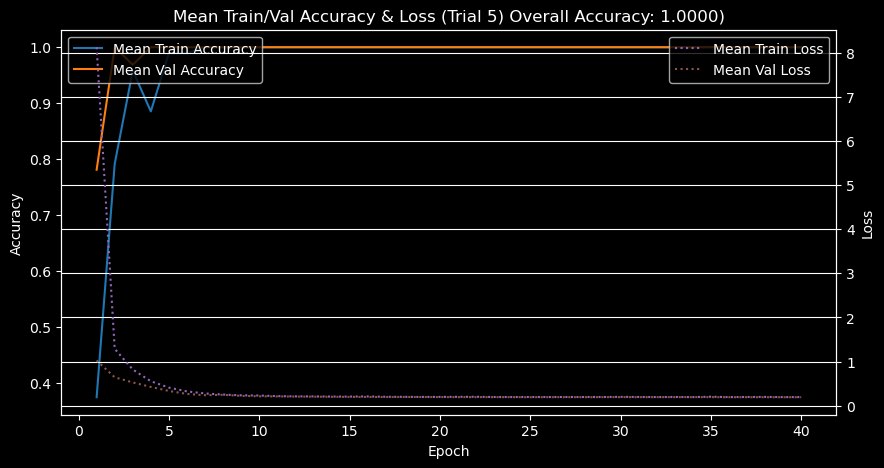

[I 2025-06-01 23:00:40,761] Trial 4 finished with value: 1.0 and parameters: {'window_size': 8, 'conv3_filters': 256, 'conv1_kernel_shape': (3, 3), 'conv2_kernel_shape': (5, 5), 'conv3_kernel_shape': (3, 3), 'padding1': 2, 'padding2': 1, 'padding3': 2, 'conv1_activation': 'gelu', 'conv2_activation': 'leaky_relu', 'conv3_activation': 'elu', 'dense_nodes': 256, 'dense_activation': 'gelu', 'lstm1_cells': 64, 'lstm2_cells': 64, 'dense3_nodes': 64, 'dense3_activation': 'gelu', 'learning_rate': 0.000512740758649487, 'batch_size': 8, 'dropout_rate': 0.05, 'optimizer': 'adam', 'weight_decay': 1.5854280248973426e-06, 'label_smoothing': 0.05, 'number_of_heads': 2}. Best is trial 0 with value: 1.0.


Trial 4 - Best Avg Val Acc: 1.0, Best Avg Val Loss: 0.2433164619630383


In [9]:
import optuna
import json

number_of_trials = 5 # Number of trials for Optuna
number_of_folds = 4 # 2 # Number of folds for cross-validation
# Split on task type or patient id 
property_to_split_on = "task_type_cat" # "patient_id"  # Property to split on for cross-validation

# Prepare a global DataFrame for metrics
all_metrics_df = utils.create_metrics_df()


# Define a wrapper so Optuna only gets the accuracy
def optuna_objective(trial):
    global all_metrics_df

    plot_path = f"{output_dir}/{which_dataset}/optuna_plots_{model_name}_trial_{trial.number}_timestamp_{timestamp}.png"

    best_avg_val_acc, best_avg_val_loss, updated_metrics_df = utils.objective(
        trial, all_metrics_df, train_data, train_df, device,
        n_splits=number_of_folds, best_model_path=model_pth_path, plot_path=plot_path,
        property_to_split_on=property_to_split_on
    )
    all_metrics_df = updated_metrics_df  # update global after each trial
    print(f"Trial {trial.number} - Best Avg Val Acc: {best_avg_val_acc}, Best Avg Val Loss: {best_avg_val_loss}")
    return best_avg_val_acc  # maximize accuracy

# Run Optuna and save best model after all trials
study = optuna.create_study(direction="maximize")  # or "maximize" based on your objective
study.optimize(optuna_objective, n_trials=number_of_trials)

### Training stage #2 train on full train dataset with best paramters chosen

Epoch 1/50 - Acc: 0.4375 - F1: 0.4234 - Loss: 4.7498
Epoch 11/50 - Acc: 1.0000 - F1: 1.0000 - Loss: 0.4696
Epoch 21/50 - Acc: 1.0000 - F1: 1.0000 - Loss: 0.4586
Epoch 31/50 - Acc: 1.0000 - F1: 1.0000 - Loss: 0.4469
Epoch 41/50 - Acc: 1.0000 - F1: 1.0000 - Loss: 0.4702
Epoch 50/50 - Acc: 1.0000 - F1: 1.0000 - Loss: 0.4559
Total Train Accuracy: 0.9738


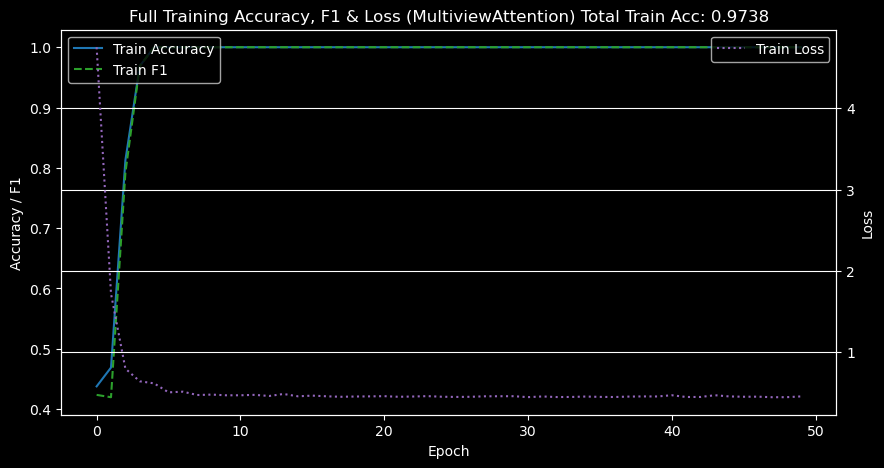

In [10]:
import importlib
importlib.reload(utils)

best_model, best_params, _, train_accs, train_f1s, train_losses = utils.train_full_model(
    study,
    train_data,
    train_df,
    device,
    epochs=50
)

### Training stage #3 saving the final model

In [11]:
# Create the model with the best hyperparameters
torch.save(best_model.state_dict(), model_pth_path)
print(f"Best model saved to {model_pth_path}")

# Save the best hyperparameters to a JSON file
with open(model_json_path, "w") as json_file:
    json.dump(best_params, json_file, indent=4)
print(f"Best hyperparameters saved to {model_json_path}")

Best model saved to ./Models/intra/best_model_MultiviewAttention_intra_20250601_225149.pth
Best hyperparameters saved to ./Models/intra/best_model_MultiviewAttention_intra_20250601_225149.json


### Evaluate model and save logs

In [12]:
import importlib
importlib.reload(utils)

test_metrics, df_test_result, all_metrics_df = utils.evaluate_and_log_testset(
    study,
    best_model,
    best_params,
    test_data,
    test_df,
    device,
    all_metrics_df,
    model_csv_path,
    output_dir,
    which_dataset,
    model_name,
    timestamp
)

Test metrics: {'overall_accuracy': 1.0, 'overall_F1': 1.0, 'overall_recall': 1.0, 'overall_precision': 1.0, 'resting_accuracy': 1.0, 'resting_F1': 1.0, 'resting_recall': 1.0, 'resting_precision': 1.0, 'math_accuracy': 1.0, 'math_F1': 1.0, 'math_recall': 1.0, 'math_precision': 1.0, 'memory_accuracy': 1.0, 'memory_F1': 1.0, 'memory_recall': 1.0, 'memory_precision': 1.0, 'motor_accuracy': 1.0, 'motor_F1': 1.0, 'motor_recall': 1.0, 'motor_precision': 1.0} 
Best trial ID: 1 

All metrics saved to ./Output/intra/best_model_MultiviewAttention_intra_20250601_225149.csv
Best hyperparameters: {'window_size': 8, 'conv3_filters': 64, 'conv1_kernel_shape': (5, 5), 'conv2_kernel_shape': (3, 3), 'conv3_kernel_shape': (5, 5), 'padding1': 2, 'padding2': 1, 'padding3': 2, 'conv1_activation': 'gelu', 'conv2_activation': 'leaky_relu', 'conv3_activation': 'elu', 'dense_nodes': 128, 'dense_activation': 'relu', 'lstm1_cells': 32, 'lstm2_cells': 64, 'dense3_nodes': 64, 'dense3_activation': 'relu', 'learning_r

c:\Users\bar24\OneDrive - Universiteit Utrecht\Documents\School\UU Data Sceince MSc\1st Year\Period 4\Deep learning (INFOMDLR)\Assignments\Deep_Learning_MEG\utils.py:1128: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(fontsize=16, loc='upper left', bbox_to_anchor=(1.05, 1.0))


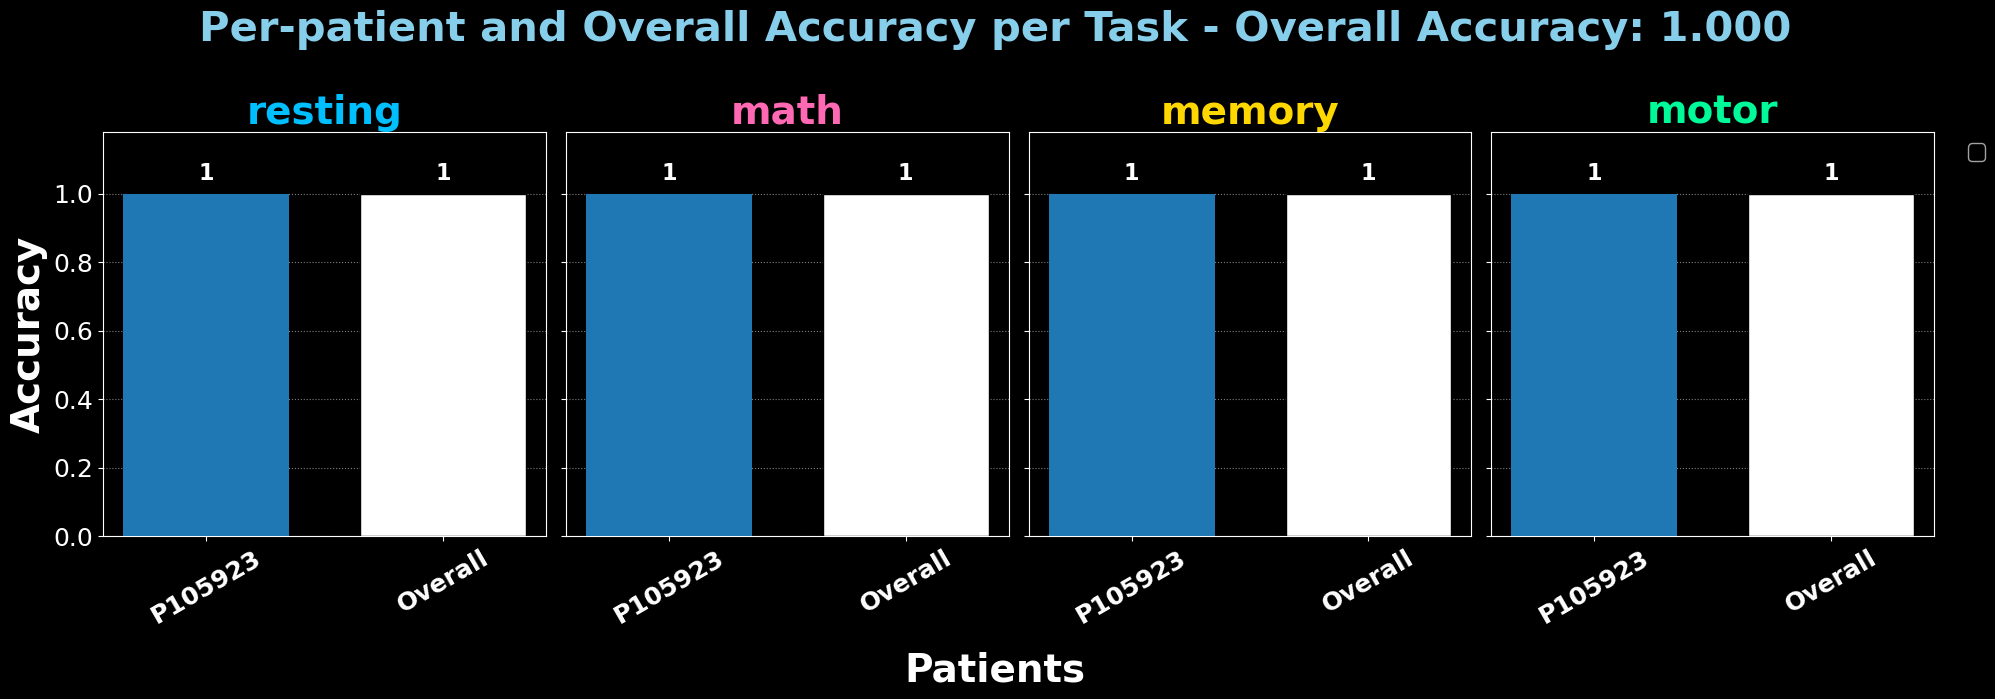

In [13]:
import importlib
importlib.reload(utils)

fig, axs, path, per_patient_acc, overall_acc_per_task = utils.plot_per_patient_accuracy_bars(
    df_test_result,
    output_dir,
    which_dataset,
    model_name,
    timestamp,
    task_names=["resting", "math", "memory", "motor"]
)

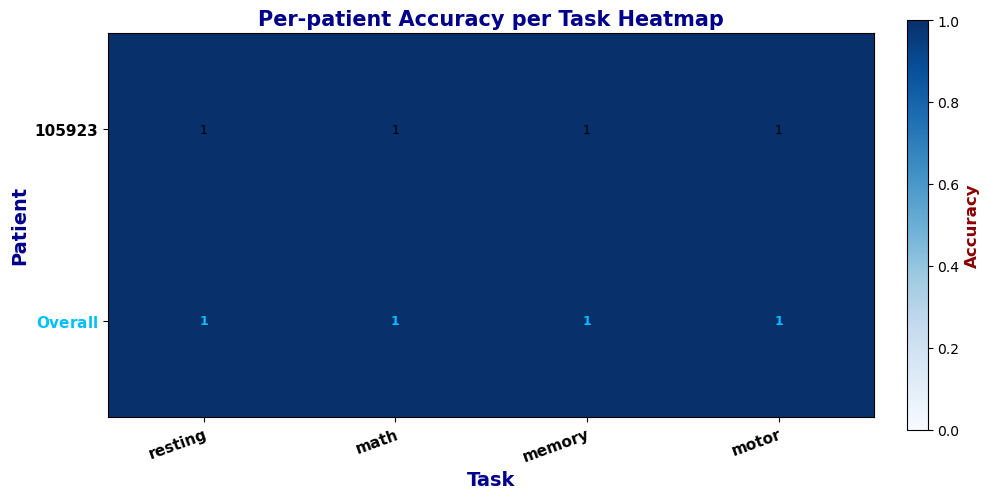

(<Figure size 1000x600 with 2 Axes>,
 <Axes: title={'center': 'Per-patient Accuracy per Task Heatmap'}, xlabel='Task', ylabel='Patient'>,
 './Output/intra/per_patient_accuracy_heatmap_MultiviewAttention_intra_20250601_225149.png')

In [14]:
import importlib
importlib.reload(utils)

utils.plot_per_patient_accuracy_heatmap(
    per_patient_acc,
    overall_acc_per_task,
    df_test_result,
    output_dir,
    which_dataset,
    model_name,
    timestamp,
    task_names=["resting", "math", "memory", "motor"]
)

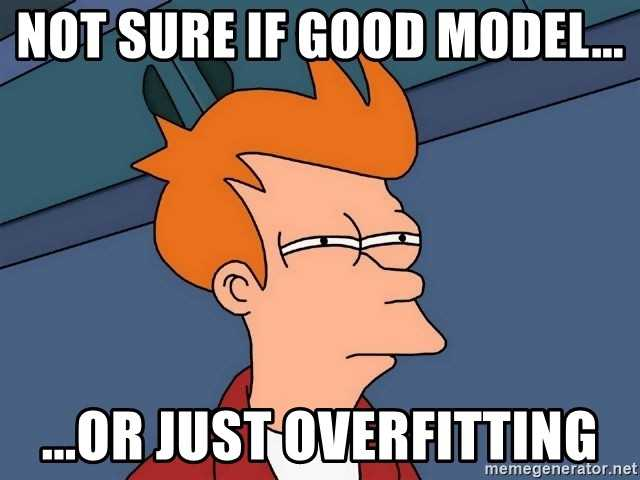

In [15]:
from IPython.display import Image, display

display(Image(filename="overfitunsurefry.webp"))

### Display first few lines from logs

In [16]:
from IPython.display import display, HTML

# Show the first 10 rows of the DataFrame in a scrollable box
display(HTML(all_metrics_df.head(10).to_html(max_rows=10, max_cols=100, notebook=True, show_dimensions=True, justify='center', border=1, table_id="scroll_df")))

,trial_id,epoch,train_overall_accuracy,train_overall_F1,train_overall_recall,train_overall_precision,train_resting_accuracy,train_resting_F1,train_resting_recall,train_resting_precision,train_math_accuracy,train_math_F1,train_math_recall,train_math_precision,train_memory_accuracy,train_memory_F1,train_memory_recall,train_memory_precision,train_motor_accuracy,train_motor_F1,train_motor_recall,train_motor_precision,val_overall_accuracy,val_overall_F1,val_overall_recall,val_overall_precision,val_resting_accuracy,val_resting_F1,val_resting_recall,val_resting_precision,val_math_accuracy,val_math_F1,val_math_recall,val_math_precision,val_memory_accuracy,val_memory_F1,val_memory_recall,val_memory_precision,val_motor_accuracy,val_motor_F1,val_motor_recall,val_motor_precision,test_overall_accuracy,test_overall_F1,test_overall_recall,test_overall_precision,test_resting_accuracy,test_resting_F1,test_resting_recall,test_resting_precision,test_math_accuracy,test_math_F1,test_math_recall,test_math_precision,test_memory_accuracy,test_memory_F1,test_memory_recall,test_memory_precision,test_motor_accuracy,test_motor_F1,test_motor_recall,test_motor_precision,window_size,conv1_filters,conv2_filters,conv3_filters,conv1_kernel_shape,conv2_kernel_shape,conv3_kernel_shape,padding1,padding2,padding3,conv1_activation,conv2_activation,conv3_activation,dense_nodes,dense_activation,depth,lstm1_cells,lstm2_cells,dense3_nodes,dense3_activation,number_classes,number_channels,mesh_rows,mesh_columns,split_size,learning_rate,batch_size,dropout_rate,optimizer,weight_decay,label_smoothing,number_of_heads,fold_index,train_loss,val_loss
0,1,1,0.375000,0.400787,0.375000,0.521429,0.333333,0.166667,0.111111,0.333333,0.333333,0.25,0.166667,0.5,0.333333,0.250000,0.166667,0.500000,0.500000,0.222222,0.166667,0.333333,0.25,0.100000,0.25,0.0625,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,8,128,256,64,"(5, 5)","(3, 3)","(5, 5)",2,1,2,gelu,leaky_relu,elu,128,relu,1,32,64,64,relu,4,248,8,31,636,0.001016,8,0.1,adam,8.687348e-07,0.15,2,1.0,6.019265,4.149592
1,1,2,0.291667,0.250000,0.291667,0.218750,0.166667,0.095238,0.055556,0.333333,0.000000,0.00,0.000000,0.0,0.666667,0.266667,0.222222,0.333333,0.333333,0.166667,0.111111,0.333333,0.50,0.333333,0.50,0.2500,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8,128,256,64,"(5, 5)","(3, 3)","(5, 5)",2,1,2,gelu,leaky_relu,elu,128,relu,1,32,64,64,relu,4,248,8,31,636,0.001016,8,0.1,adam,8.687348e-07,0.15,2,1.0,4.361825,1.248346
2,1,3,0.625000,0.559524,0.625000,0.600000,0.000000,0.000000,0.000000,0.000000,1.000000,1.00,1.000000,1.0,1.000000,1.000000,1.000000,1.000000,0.500000,0.333333,0.250000,0.500000,0.50,0.333333,0.50,0.2500,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8,128,256,64,"(5, 5)","(3, 3)","(5, 5)",2,1,2,gelu,leaky_relu,elu,128,relu,1,32,64,64,relu,4,248,8,31,636,0.001016,8,0.1,adam,8.687348e-07,0.15,2,1.0,1.051991,0.886874
3,1,4,0.750000,0.726786,0.750000,0.837500,0.333333,0.250000,0.166667,0.500000,1.000000,1.00,1.000000,1.0,0.666667,0.400000,0.333333,0.500000,1.000000,1.000000,1.000000,1.000000,1.00,1.000000,1.00,1.0000,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8,128,256,64,"(5, 5)","(3, 3)","(5, 5)",2,1,2,gelu,leaky_relu,elu,128,relu,1,32,64,64,relu,4,248,8,31,636,0.001016,8,0.1,adam,8.687348e-07,0.15,2,1.0,0.787949,0.583473
4,1,5,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00,1.000000,1.0,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.75,0.666667,0.75,0.6250,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Na

### Plot plots

In [17]:
print("we are done, goodbye!")

we are done, goodbye!
